In [70]:
!git clone -b segmentation https://github.com/BatoolAshour/Sand-Dune-Segmentation.git

fatal: destination path 'Sand-Dune-Segmentation' already exists and is not an empty directory.


In [71]:
%cd /content/Sand-Dune-Segmentation
!git branch --show-current

/content/Sand-Dune-Segmentation
segmentation


In [72]:
# Import Libraries
from pathlib import Path
import re
import os
import numpy as np
import pandas as pd
import rasterio
from skimage.filters import threshold_otsu
import matplotlib.pyplot as plt

Image Data Inspection

In [73]:
base = Path("Processed Dataset")

print("Dataset exists:", base.exists())
print("Available folders:", list(base.iterdir()))

Dataset exists: True
Available folders: [PosixPath('Processed Dataset/validation_issues.csv'), PosixPath('Processed Dataset/README.md'), PosixPath('Processed Dataset/visualizations'), PosixPath('Processed Dataset/masks'), PosixPath('Processed Dataset/run_summary.json'), PosixPath('Processed Dataset/verification_summary.json'), PosixPath('Processed Dataset/geotiff'), PosixPath('Processed Dataset/preprocessing_report.csv')]


In [74]:
geotiff_path = base / "geotiff"

years = sorted([folder.name for folder in geotiff_path.iterdir() if folder.is_dir()])

print("Available years:", years)

Available years: ['2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']


In [75]:
image_path = base / "geotiff/2020/L1_Abqaiq_N_2020_processed.tif"

with rasterio.open(image_path) as src:
    image = src.read()

    print("Image shape:", image.shape)
    print("Data type:", image.dtype)
    print("Number of bands:", src.count)
    print("CRS:", src.crs)

Image shape: (6, 400, 400)
Data type: float32
Number of bands: 6
CRS: EPSG:32639


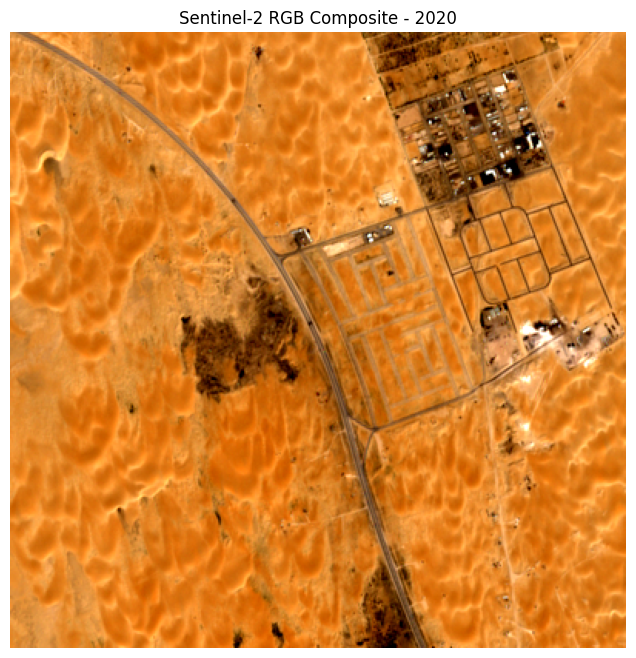

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# Select RGB bands
red = image[2]
green = image[1]
blue = image[0]

rgb = np.dstack((red, green, blue))

# Normalize for visualization only
p2, p98 = np.nanpercentile(rgb, (2, 98))
rgb_display = np.clip((rgb - p2) / (p98 - p2), 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(rgb_display)
plt.title("Sentinel-2 RGB Composite - 2020")
plt.axis("off")
plt.show()

Bare Soil Index (BSI) Calculation


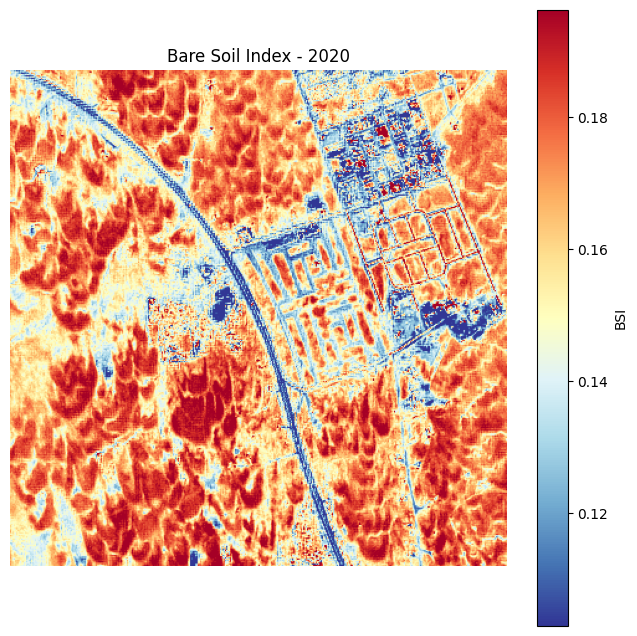

In [97]:
# Calculate Bare Soil Index
B02 = image[0]
B04 = image[2]
B08 = image[3]
B11 = image[4]

numerator = (B11 + B04) - (B08 + B02)
denominator = (B11 + B04) + (B08 + B02)

bsi = np.divide(
    numerator,
    denominator,
    out=np.full_like(numerator, np.nan),
    where=np.abs(denominator) > 1e-10
)

# Display BSI using actual value range
bsi_values = bsi[np.isfinite(bsi)]

bsi_min = np.percentile(bsi_values, 2)
bsi_max = np.percentile(bsi_values, 98)

plt.figure(figsize=(8, 8))
plt.imshow(bsi, cmap="RdYlBu_r", vmin=bsi_min, vmax=bsi_max)
plt.colorbar(label="BSI")
plt.title("Bare Soil Index - 2020")
plt.axis("off")
plt.show()

In [98]:
# Load the valid pixel mask
valid_path = base / "masks/2020/L1_Abqaiq_N_2020_valid.tif"

with rasterio.open(valid_path) as src:
    valid_mask = src.read(1).astype(bool)

# Keep only valid and finite BSI values
bsi_values = bsi[valid_mask & np.isfinite(bsi)]

# Print statistics
print("Minimum:", np.min(bsi_values))
print("Maximum:", np.max(bsi_values))
print("Mean:", np.mean(bsi_values))
print("Median:", np.median(bsi_values))

print("2nd percentile:", np.percentile(bsi_values, 2))
print("98th percentile:", np.percentile(bsi_values, 98))

Minimum: -0.16569531
Maximum: 0.37797165
Mean: 0.16123657
Median: 0.1647535
2nd percentile: 0.10289389
98th percentile: 0.1962789


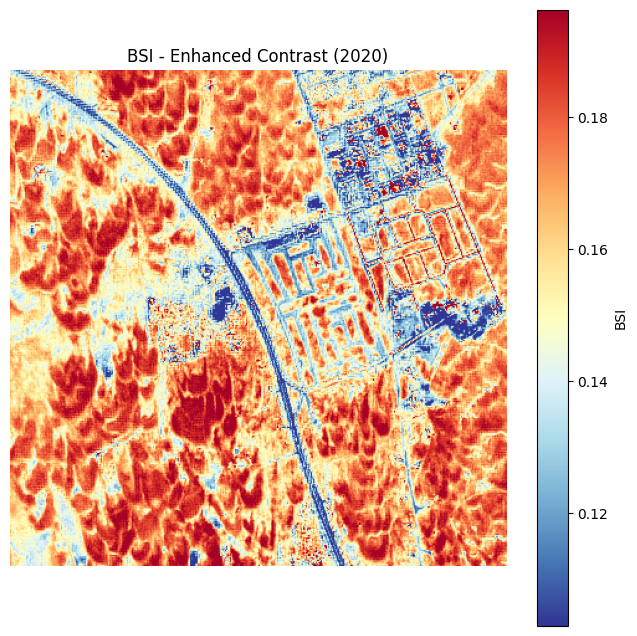

In [99]:
vmin, vmax = np.percentile(bsi_values, [2, 98])

bsi_display = np.ma.masked_where(
    ~valid_mask | ~np.isfinite(bsi), bsi
)

plt.figure(figsize=(8, 8))
plt.imshow(bsi_display, cmap="RdYlBu_r", vmin=vmin, vmax=vmax)
plt.colorbar(label="BSI")
plt.title("BSI - Enhanced Contrast (2020)")
plt.axis("off")
plt.show()

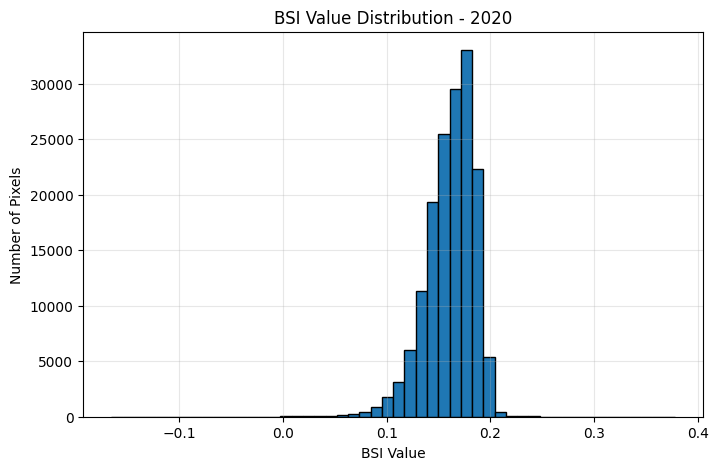

In [100]:
plt.figure(figsize=(8, 5))

plt.hist(bsi_values, bins=50, edgecolor="black")

plt.xlabel("BSI Value")
plt.ylabel("Number of Pixels")
plt.title("BSI Value Distribution - 2020")
plt.grid(alpha=0.3)

plt.show()

Otsu Thresholding and Binary Segmentation

In [101]:
from skimage.filters import threshold_otsu

# Select valid BSI pixels
bsi_valid = bsi[valid_mask & np.isfinite(bsi)]

# Calculate the automatic threshold
otsu_threshold = threshold_otsu(bsi_valid)

# Classify pixels into two classes
sand_mask = (bsi > otsu_threshold) & valid_mask

print("Otsu Threshold:", otsu_threshold)
print("Potential Sand Pixels:", np.sum(sand_mask))
print("Potential Sand Percentage:",
      (np.sum(sand_mask) / np.sum(valid_mask)) * 100)

Otsu Threshold: 0.1539214
Potential Sand Pixels: 106750
Potential Sand Percentage: 66.71875


In [102]:
# Get valid BSI values
bsi_values = bsi[valid_mask & np.isfinite(bsi)]

# Calculate display range
bsi_min = np.min(bsi_values)
bsi_max = np.max(bsi_values)

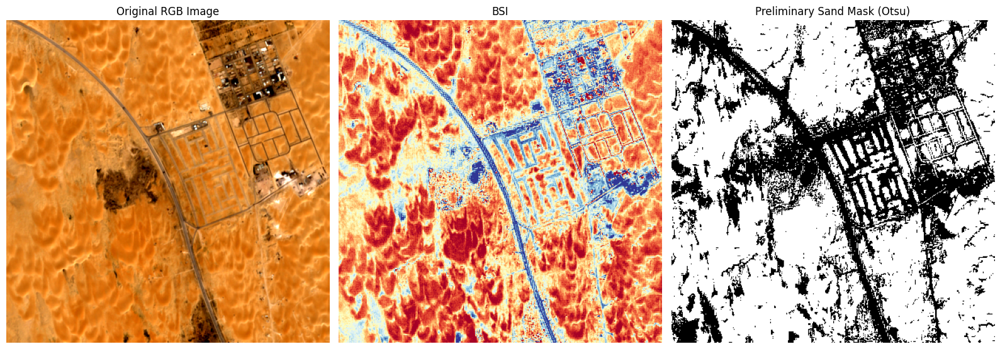

In [104]:
# Display the original image and segmentation result
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Original RGB image
axes[0].imshow(rgb_display)
axes[0].set_title("Original RGB Image")

# BSI with enhanced contrast
axes[1].imshow(
    bsi,
    cmap="RdYlBu_r",
    vmin=np.percentile(bsi_values, 2),
    vmax=np.percentile(bsi_values, 98)
)
axes[1].set_title("BSI")

# Otsu segmentation mask
axes[2].imshow(sand_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Preliminary Sand Mask (Otsu)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

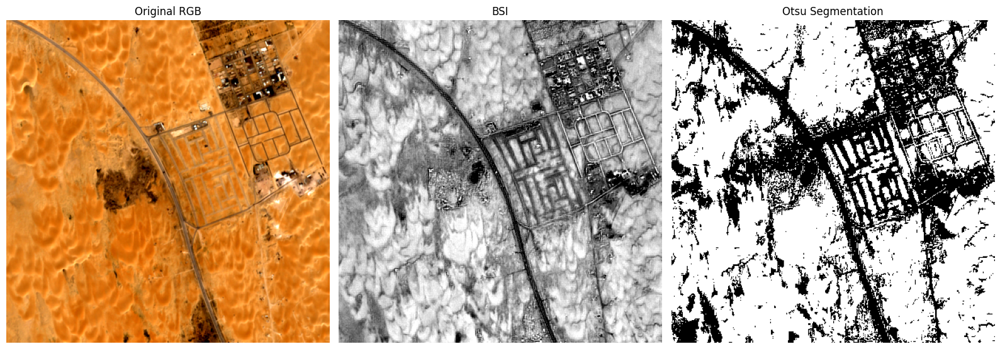

In [105]:
# Display RGB, BSI, and Otsu segmentation
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Original RGB
axes[0].imshow(rgb_display)
axes[0].set_title("Original RGB")

# BSI with enhanced contrast
axes[1].imshow(
    bsi,
    cmap="gray",
    vmin=np.nanpercentile(bsi, 2),
    vmax=np.nanpercentile(bsi, 98)
)
axes[1].set_title("BSI")

# Otsu segmentation
axes[2].imshow(sand_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Otsu Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [106]:
# Select valid BSI pixels
valid_pixels = valid_mask & np.isfinite(bsi)

# Calculate Otsu threshold
bsi_threshold = threshold_otsu(bsi[valid_pixels])

# Create BSI-based segmentation mask
combined_mask = (bsi > bsi_threshold) & valid_pixels

# Display results
print("BSI Otsu Threshold:", bsi_threshold)
print("Potential Sand Pixels:", np.sum(combined_mask))
print("Potential Sand Percentage:",
      np.sum(combined_mask) / np.sum(valid_mask) * 100)

BSI Otsu Threshold: 0.1539214
Potential Sand Pixels: 106750
Potential Sand Percentage: 66.71875


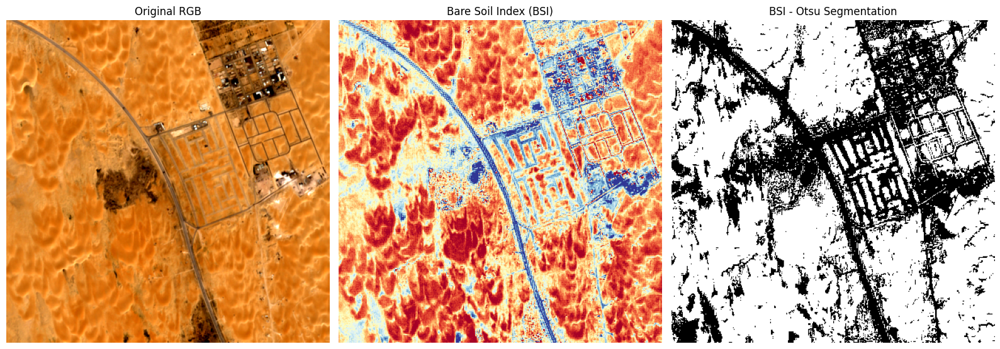

In [108]:
# Display the original image, BSI, and segmentation result
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(rgb_display)
axes[0].set_title("Original RGB")

# Use consistent BSI display range
axes[1].imshow(
    bsi,
    cmap="RdYlBu_r",
    vmin=0.10289389,
    vmax=0.1962789
)
axes[1].set_title("Bare Soil Index (BSI)")

axes[2].imshow(sand_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("BSI - Otsu Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [109]:
image_files = sorted(
    Path("Processed Dataset/geotiff").glob("*/*.tif")
)

mask_files = sorted(
    Path("Processed Dataset/masks").glob("*/*_valid.tif")
)

image_names = {
    (f.parent.name, f.stem.replace("_processed", ""))
    for f in image_files
}

mask_names = {
    (f.parent.name, f.stem.replace("_valid", ""))
    for f in mask_files
}

missing_masks = image_names - mask_names

print("Images:", len(image_files))
print("Valid masks:", len(mask_files))
print("Images without matching masks:", len(missing_masks))

for item in sorted(missing_masks):
    print(item)

Images: 200
Valid masks: 200
Images without matching masks: 0


In [112]:
# Input folders
dataset = Path("Processed Dataset")
geotiff_path = dataset / "geotiff"
masks_path = dataset / "masks"

# Output folder
output_dir = Path("Segmentation/Results_BSI_Otsu")
output_dir.mkdir(parents=True, exist_ok=True)

# Load all images
image_files = sorted(geotiff_path.glob("*/*.tif"))

if len(image_files) != 200:
    raise ValueError(f"Expected 200 images, found {len(image_files)}")

# Match images with valid masks
pairs = []

for image_file in image_files:
    year = image_file.parent.name

    mask_name = image_file.stem.replace(
        "_processed", "_valid"
    ) + ".tif"

    valid_file = masks_path / year / mask_name

    if not valid_file.exists():
        raise FileNotFoundError(valid_file)

    pairs.append((image_file, valid_file))

# Expected output files
expected_outputs = [
    output_dir / (
        f.stem.replace("_processed", "_BSI_Otsu_mask") + ".tif"
    )
    for f in image_files
]

csv_file = output_dir / "BSI_Otsu_Summary.csv"

# Check whether all results already exist
all_results_exist = (
    all(f.exists() for f in expected_outputs)
    and csv_file.exists()
)

if all_results_exist:
    summary = pd.read_csv(csv_file)

    if len(summary) == 200:
        # Ensure correct year values
        summary["Year"] = summary["Image"].str.extract(
            r"_(\d{4})_processed\.tif$"
        )[0].astype(int)

        summary.to_csv(csv_file, index=False)

        print("All 200 segmentation results already exist.")
        print("Existing results will be reused.")
        print("Total images:", len(summary))
        print("Summary file:", csv_file)

    else:
        all_results_exist = False

if not all_results_exist:

    results = []

    # Process all images and save only missing masks
    for i, (image_file, valid_file) in enumerate(pairs, start=1):

        year = image_file.parent.name

        with rasterio.open(image_file) as src:
            image = src.read().astype(np.float32)
            profile = src.profile.copy()

        with rasterio.open(valid_file) as src:
            valid_mask = src.read(1) == 1

        # Extract spectral bands
        blue = image[0]
        red = image[2]
        nir = image[3]
        swir1 = image[4]

        # Calculate BSI
        numerator = (swir1 + red) - (nir + blue)
        denominator = (swir1 + red) + (nir + blue)

        bsi = np.divide(
            numerator,
            denominator,
            out=np.full_like(numerator, np.nan),
            where=np.abs(denominator) > 1e-10
        )

        valid_pixels = valid_mask & np.isfinite(bsi)

        if not np.any(valid_pixels):
            raise ValueError(f"No valid pixels: {image_file.name}")

        # Apply Otsu thresholding
        threshold = threshold_otsu(bsi[valid_pixels])

        # Generate segmentation mask
        output_mask = np.full(bsi.shape, 255, dtype=np.uint8)

        output_mask[valid_pixels] = (
            bsi[valid_pixels] > threshold
        ).astype(np.uint8)

        # Save only if output does not already exist
        output_name = image_file.stem.replace(
            "_processed", "_BSI_Otsu_mask"
        ) + ".tif"

        output_path = output_dir / output_name

        if not output_path.exists():

            profile.update(
                driver="GTiff",
                count=1,
                dtype="uint8",
                nodata=255,
                compress="lzw"
            )

            profile.pop("blockxsize", None)
            profile.pop("blockysize", None)

            with rasterio.open(output_path, "w", **profile) as dst:
                dst.write(output_mask, 1)

        # Calculate statistics
        sand_pixels = int(np.sum(output_mask == 1))
        valid_count = int(np.sum(valid_pixels))
        sand_percentage = sand_pixels / valid_count * 100

        results.append({
            "Image": image_file.name,
            "Year": int(year),
            "Otsu_Threshold": float(threshold),
            "Potential_Sand_Pixels": sand_pixels,
            "Valid_Pixels": valid_count,
            "Potential_Sand_Percentage": sand_percentage
        })

        print(f"[{i}/200] Checked: {image_file.name}")

    # Export summary
    summary = pd.DataFrame(results)
    summary.to_csv(csv_file, index=False)

    print("\nProcessing completed!")
    print("Total images:", len(summary))
    print("Output folder:", output_dir)
    print("Summary file:", csv_file)


All 200 segmentation results already exist.
Existing results will be reused.
Total images: 200
Summary file: Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv


In [113]:
# Load the existing summary
summary = pd.read_csv(
    "Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv"
)

# Extract the correct year from each image filename
summary["Year"] = summary["Image"].str.extract(
    r"_(\d{4})_processed\.tif$"
)[0].astype(int)

# Save the corrected summary
summary.to_csv(
    "Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv",
    index=False
)

print("Year column corrected successfully!")

# Display the selected location results
selected_site = "L1_Abqaiq_N"

site_summary = summary[
    summary["Image"].str.startswith(selected_site + "_")
].sort_values("Year")

display(
    site_summary[
        ["Image", "Year", "Otsu_Threshold",
         "Potential_Sand_Percentage"]
    ].reset_index(drop=True)
)

Year column corrected successfully!


,Image,Year,Otsu_Threshold,Potential_Sand_Percentage
0,L1_Abqaiq_N_2019_processed.tif,2019,0.156704,70.046875
1,L1_Abqaiq_N_2020_processed.tif,2020,0.153921,66.718750
2,L1_Abqaiq_N_2021_processed.tif,2021,0.169413,59.550625
3,L1_Abqaiq_N_2022_processed.tif,2022,0.165181,60.998125
4,L1_Abqaiq_N_2023_processed.tif,2023,0.170840,57.421250
5,L1_Abqaiq_N_2024_processed.tif,2024,0.156524,69.509375
6,L1_Abqaiq_N_2025_processed.tif,2025,0.159965,62.116553
7,L1_Abqaiq_N_2026_processed.tif,2026,0.157383,64.554375


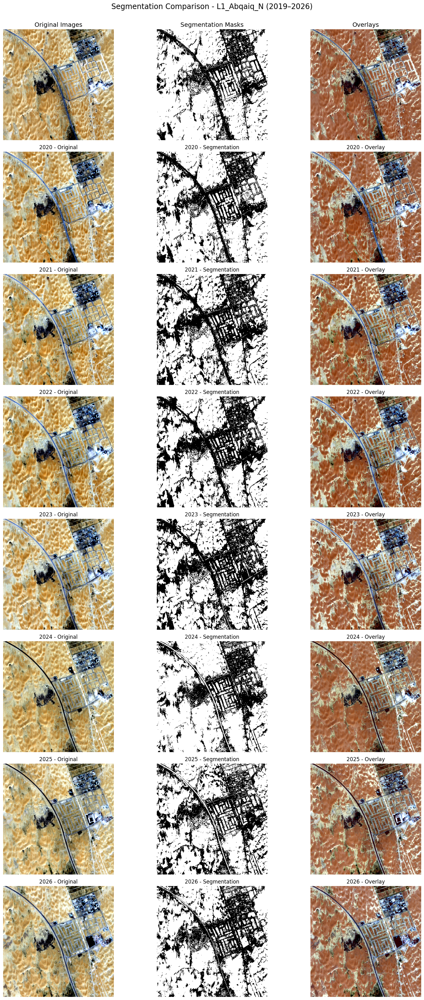

In [114]:
# Define folders
geotiff_path = Path("Processed Dataset/geotiff")
results_path = Path("Segmentation/Results_BSI_Otsu")

selected_site = "L1_Abqaiq_N"
years = range(2019, 2027)

# Create comparison figure
fig, axes = plt.subplots(8, 3, figsize=(16, 32))

for row, year in enumerate(years):

    # Find the image for this location and year
    image_file = (
        geotiff_path / str(year) /
        f"{selected_site}_{year}_processed.tif"
    )

    mask_file = (
        results_path /
        f"{selected_site}_{year}_BSI_Otsu_mask.tif"
    )

    if not image_file.exists():
        raise FileNotFoundError(image_file)

    if not mask_file.exists():
        raise FileNotFoundError(mask_file)

    # Read original image
    with rasterio.open(image_file) as src:
        image = src.read([3, 2, 1]).astype(np.float32)

    # Read segmentation mask
    with rasterio.open(mask_file) as src:
        mask = src.read(1)

    # Prepare RGB display
    rgb = np.moveaxis(image, 0, -1)
    rgb_display = np.zeros_like(rgb)

    for channel in range(3):
        band = rgb[:, :, channel]
        valid = np.isfinite(band)

        if np.any(valid):
            low, high = np.percentile(
                band[valid], [2, 98]
            )

            rgb_display[:, :, channel] = np.clip(
                (band - low) / (high - low + 1e-8),
                0, 1
            )

    # Original image
    axes[row, 0].imshow(rgb_display)
    axes[row, 0].set_title(f"{year} - Original")

    # Segmentation mask
    display_mask = np.ma.masked_where(mask == 255, mask)

    axes[row, 1].imshow(
        display_mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title(f"{year} - Segmentation")

    # Overlay
    axes[row, 2].imshow(rgb_display)

    sand_overlay = np.ma.masked_where(mask != 1, mask)

    axes[row, 2].imshow(
        sand_overlay,
        cmap="Reds",
        alpha=0.4,
        vmin=0,
        vmax=1
    )

    axes[row, 2].set_title(f"{year} - Overlay")

    for ax in axes[row]:
        ax.axis("off")

# Add column headings
axes[0, 0].set_title("Original Images", fontsize=14)
axes[0, 1].set_title("Segmentation Masks", fontsize=14)
axes[0, 2].set_title("Overlays", fontsize=14)

plt.suptitle(
    f"Segmentation Comparison - {selected_site} (2019–2026)",
    fontsize=17,
    y=1.002
)

plt.tight_layout()
plt.show()



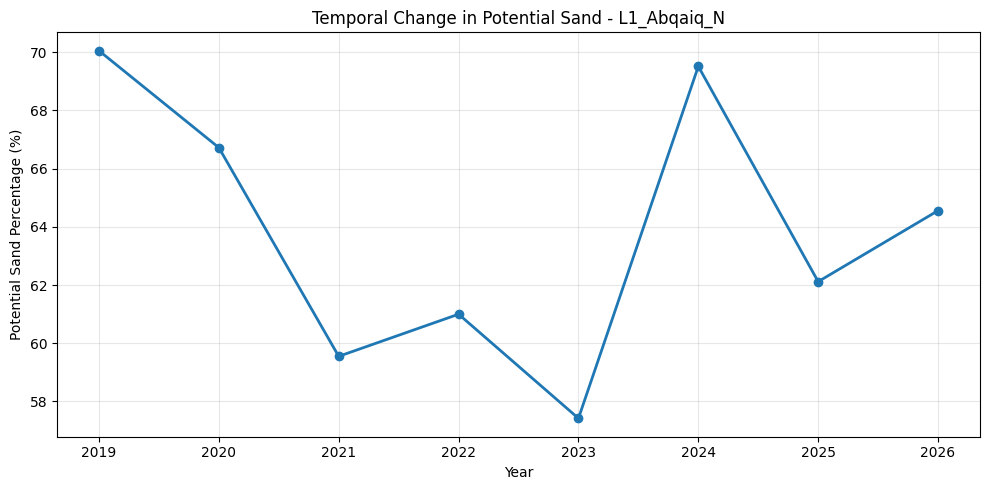

In [115]:
# Sort results by year
site_summary = site_summary.sort_values("Year")

plt.figure(figsize=(10, 5))

plt.plot(
    site_summary["Year"],
    site_summary["Potential_Sand_Percentage"],
    marker="o",
    linewidth=2
)

plt.xticks(range(2019, 2027))
plt.xlabel("Year")
plt.ylabel("Potential Sand Percentage (%)")
plt.title("Temporal Change in Potential Sand - L1_Abqaiq_N")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save graph for the report
plt.savefig(
    "Segmentation/L1_Abqaiq_N_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Image,Year,Otsu_Threshold,Potential_Sand_Percentage
0,L4_Salasil_S_2019_processed.tif,2019,0.150144,80.580000
1,L4_Salasil_S_2020_processed.tif,2020,0.142557,82.505625
2,L4_Salasil_S_2021_processed.tif,2021,0.157737,81.597500
3,L4_Salasil_S_2022_processed.tif,2022,0.152725,78.938125
4,L4_Salasil_S_2023_processed.tif,2023,0.160810,74.875625
5,L4_Salasil_S_2024_processed.tif,2024,0.147855,83.859375
6,L4_Salasil_S_2025_processed.tif,2025,0.151656,79.623750
7,L4_Salasil_S_2026_processed.tif,2026,0.151112,72.640625


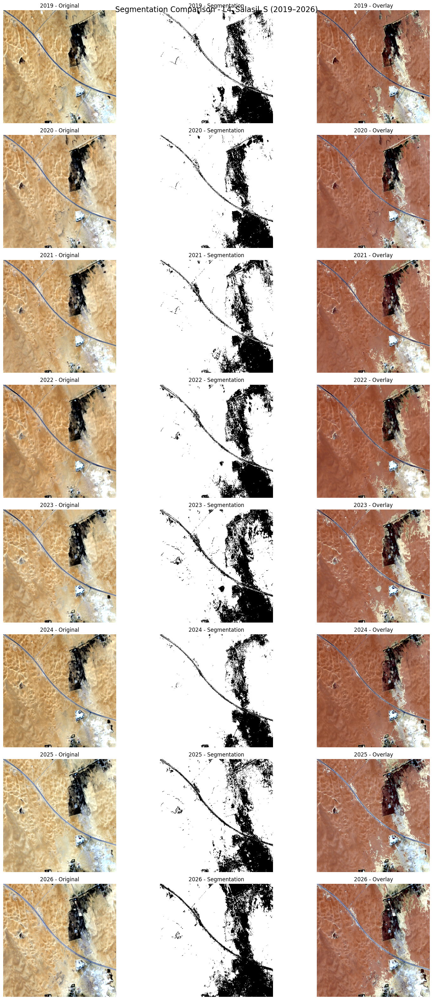

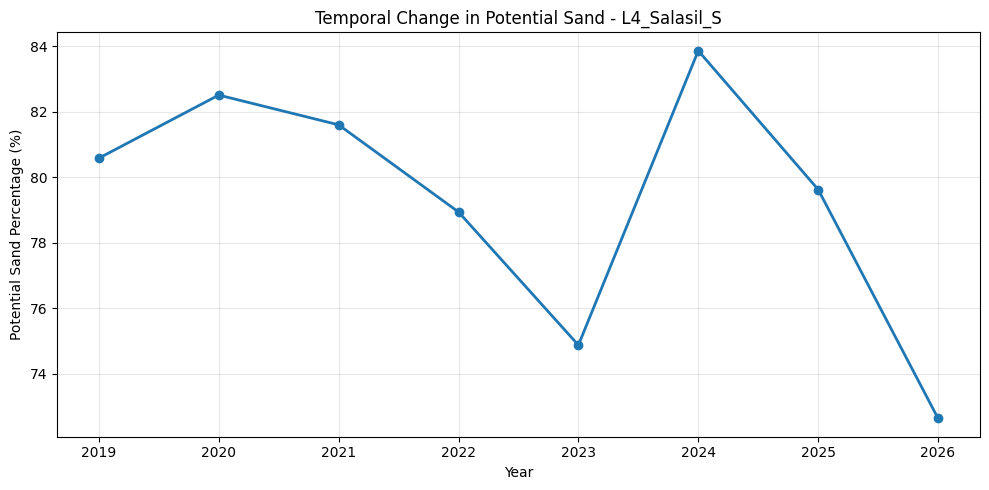

In [116]:
# Define folders
geotiff_path = Path("Processed Dataset/geotiff")
results_path = Path("Segmentation/Results_BSI_Otsu")

selected_site = "L4_Salasil_S"
years = range(2019, 2027)

# Load summary
summary = pd.read_csv(results_path / "BSI_Otsu_Summary.csv")

# Extract correct year from filenames
summary["Year"] = summary["Image"].str.extract(
    r"_(\d{4})_processed\.tif$"
)[0].astype(int)

# Select the chosen location
site_summary = summary[
    summary["Image"].str.startswith(selected_site + "_")
].sort_values("Year")

# Display yearly statistics
display(
    site_summary[
        ["Image", "Year", "Otsu_Threshold",
         "Potential_Sand_Percentage"]
    ].reset_index(drop=True)
)

# Create comparison figure
fig, axes = plt.subplots(8, 3, figsize=(16, 32))

for row, year in enumerate(years):

    # Locate image and mask
    image_file = (
        geotiff_path / str(year) /
        f"{selected_site}_{year}_processed.tif"
    )

    mask_file = (
        results_path /
        f"{selected_site}_{year}_BSI_Otsu_mask.tif"
    )

    if not image_file.exists():
        raise FileNotFoundError(image_file)

    if not mask_file.exists():
        raise FileNotFoundError(mask_file)

    # Read original image
    with rasterio.open(image_file) as src:
        image = src.read([3, 2, 1]).astype(np.float32)

    # Read segmentation mask
    with rasterio.open(mask_file) as src:
        mask = src.read(1)

    # Prepare RGB display
    rgb = np.moveaxis(image, 0, -1)
    rgb_display = np.zeros_like(rgb)

    for channel in range(3):
        band = rgb[:, :, channel]
        valid = np.isfinite(band)

        if np.any(valid):
            low, high = np.percentile(
                band[valid], [2, 98]
            )

            rgb_display[:, :, channel] = np.clip(
                (band - low) / (high - low + 1e-8),
                0, 1
            )

    # Original image
    axes[row, 0].imshow(rgb_display)
    axes[row, 0].set_title(f"{year} - Original")

    # Segmentation mask
    display_mask = np.ma.masked_where(mask == 255, mask)

    axes[row, 1].imshow(
        display_mask, cmap="gray", vmin=0, vmax=1
    )
    axes[row, 1].set_title(f"{year} - Segmentation")

    # Overlay
    axes[row, 2].imshow(rgb_display)

    sand_overlay = np.ma.masked_where(mask != 1, mask)

    axes[row, 2].imshow(
        sand_overlay, cmap="Reds",
        alpha=0.4, vmin=0, vmax=1
    )
    axes[row, 2].set_title(f"{year} - Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    f"Segmentation Comparison - {selected_site} (2019–2026)",
    fontsize=17
)

plt.tight_layout()
plt.savefig(
    f"Segmentation/{selected_site}_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Create line graph
plt.figure(figsize=(10, 5))

plt.plot(
    site_summary["Year"],
    site_summary["Potential_Sand_Percentage"],
    marker="o",
    linewidth=2
)

plt.xticks(range(2019, 2027))
plt.xlabel("Year")
plt.ylabel("Potential Sand Percentage (%)")
plt.title(f"Temporal Change in Potential Sand - {selected_site}")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"Segmentation/{selected_site}_Trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


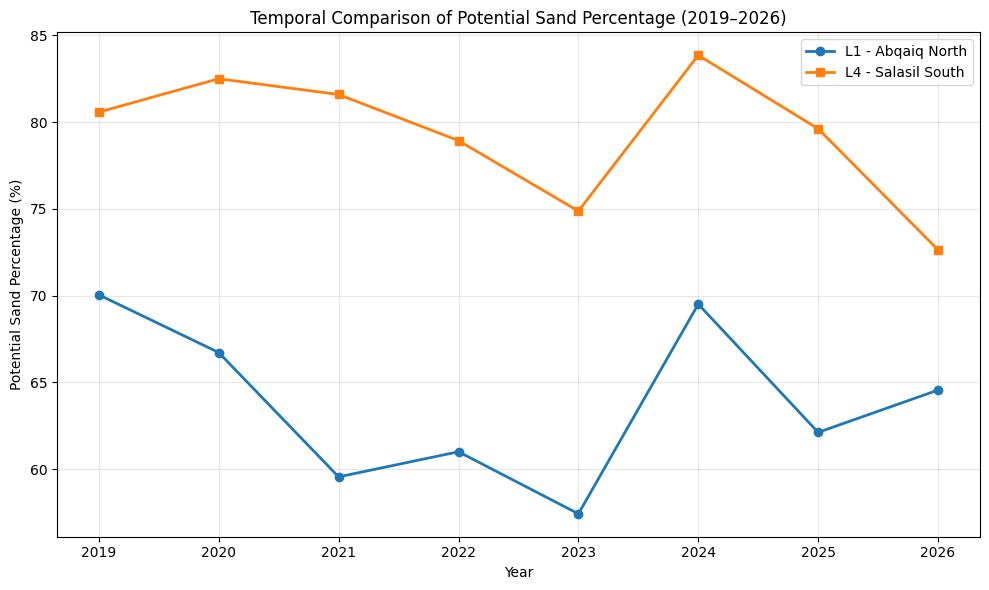

SVG saved at: Segmentation/L1_L4_Combined_Trend.svg


In [117]:
# Load summary
summary_path = "Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv"
df = pd.read_csv(summary_path)

# Extract correct year
df["Year"] = df["Image"].str.extract(
    r"_(\d{4})_processed\.tif$"
)[0].astype(int)

# Select the two sites
site1 = df[df["Image"].str.startswith("L1_Abqaiq_N_")].sort_values("Year")
site2 = df[df["Image"].str.startswith("L4_Salasil_S_")].sort_values("Year")

# Create comparison graph
plt.figure(figsize=(10, 6))

plt.plot(
    site1["Year"],
    site1["Potential_Sand_Percentage"],
    marker="o",
    linewidth=2,
    label="L1 - Abqaiq North"
)

plt.plot(
    site2["Year"],
    site2["Potential_Sand_Percentage"],
    marker="s",
    linewidth=2,
    label="L4 - Salasil South"
)

plt.title("Temporal Comparison of Potential Sand Percentage (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Potential Sand Percentage (%)")
plt.xticks(range(2019, 2027))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save as SVG
output_path = Path("Segmentation/L1_L4_Combined_Trend.svg")
plt.savefig(output_path, format="svg", bbox_inches="tight")

plt.show()

print(f"SVG saved at: {output_path}")

In [118]:
output_dir = Path("Segmentation/Results_BSI_Otsu")

mask_files = list(output_dir.glob("*_BSI_Otsu_mask.tif"))

print("Number of segmentation masks:", len(mask_files))
print("Summary CSV exists:", (output_dir / "BSI_Otsu_Summary.csv").exists())

if (output_dir / "BSI_Otsu_Summary.csv").exists():
    summary = pd.read_csv(output_dir / "BSI_Otsu_Summary.csv")
    print("Number of summary rows:", len(summary))
    display(summary.head())

Number of segmentation masks: 200
Summary CSV exists: True
Number of summary rows: 200


,Image,Year,Otsu_Threshold,Potential_Sand_Pixels,Valid_Pixels,Potential_Sand_Percentage
0,L10_DuneNE_km11_9_2019_processed.tif,2019,0.149906,113392,160000,70.870000
1,L11_DuneNE_km27_0_2019_processed.tif,2019,0.150917,86727,160000,54.204375
2,L12_DuneNE_km32_7_2019_processed.tif,2019,0.164914,119541,160000,74.713125
3,L13_SandSW_km04_9_2019_processed.tif,2019,0.149628,90344,160000,56.465000
4,L14_SandSW_km14_1_2019_processed.tif,2019,0.127635,126403,160000,79.001875


In [119]:
%cd /content/Sand-Dune-Segmentation
!git branch --show-current

/content/Sand-Dune-Segmentation
segmentation


In [120]:
!git add Segmentation/Results_BSI_Otsu/

In [121]:
!git status

On branch segmentation
Your branch is up to date with 'origin/segmentation'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2019_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2020_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2021_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2022_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2023_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2024_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2025_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2026_BSI_Otsu_mask.tif
	new file:   Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2019_BSI_Otsu_mask.tif
	new file:   Segmentation

In [125]:
!git config --global user.name "AR-254"
!git config --global user.email "2240009034@iau.edu.sa"

In [126]:
!git commit -m "Add BSI Otsu segmentation results"

[segmentation 8c4cc19] Add BSI Otsu segmentation results
 201 files changed, 201 insertions(+)
 create mode 100644 Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2019_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2020_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2021_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2022_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2023_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2024_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2025_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2026_BSI_Otsu_mask.tif
 create mode 100644 Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2019_BSI_Otsu_mask.tif
 create mode 10

In [128]:
!git status

On branch segmentation
Your branch is ahead of 'origin/segmentation' by 1 commit.
  (use "git push" to publish your local commits)

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Sand-Dune-Segmentation/
	Segmentation/L1_Abqaiq_N_Trend.png
	Segmentation/L1_L4_Combined_Trend.svg
	Segmentation/L4_Salasil_S_Comparison.png
	Segmentation/L4_Salasil_S_Trend.png

nothing added to commit but untracked files present (use "git add" to track)


In [129]:
!git diff origin/segmentation..HEAD --name-status

A	Segmentation/Results_BSI_Otsu/BSI_Otsu_Summary.csv
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2019_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2020_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2021_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2022_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2023_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2024_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2025_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L10_DuneNE_km11_9_2026_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2019_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2020_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2021_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2022_BSI_Otsu_mask.tif
A	Segmentation/Results_BSI_Otsu/L11_DuneNE_km27_0_2023_BSI_Otsu_mask.ti

In [130]:
!git push origin segmentation

fatal: could not read Username for 'https://github.com': No such device or address


In [131]:
import os
import subprocess
import getpass

token = getpass.getpass("Enter your new GitHub token: ")

askpass = "/tmp/github_askpass.sh"

with open(askpass, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""")

os.chmod(askpass, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass
env["GIT_TERMINAL_PROMPT"] = "0"
env["GITHUB_TOKEN"] = token

try:
    subprocess.run(
        ["git", "push", "origin", "segmentation"],
        env=env,
        check=True
    )
    print("Push completed successfully!")
except subprocess.CalledProcessError:
    print("Push failed. Send me the error message.")
finally:
    token = None
    env.pop("GITHUB_TOKEN", None)

Enter your new GitHub token: ··········
Push completed successfully!
